## 6-10_Using_k-NN_for_regression

In [1]:
## 1. Load the Iris dataset and inspect its feature names.

from sklearn import datasets
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
iris = datasets.load_iris()
iris.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

In [2]:
## 2. Define the input features and target variable.

X = iris.data[:,:2]
y = iris.data[:,2]

In [3]:
## 3. Fit a linear regression model and calculate the mean squared error.

from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X, y)
print("The MSE is: {:.2}".format(np.power(y - lr.predict(X),2).mean()))

The MSE is: 0.41


In [4]:
## 4. Fit a k-NN regression model and calculate the mean squared error.

from sklearn.neighbors import KNeighborsRegressor
knnr = KNeighborsRegressor(n_neighbors=10)
knnr.fit(X, y)
print("The MSE is: {:.2}".format(np.power(y - knnr.predict(X),2).mean()))

The MSE is: 0.17


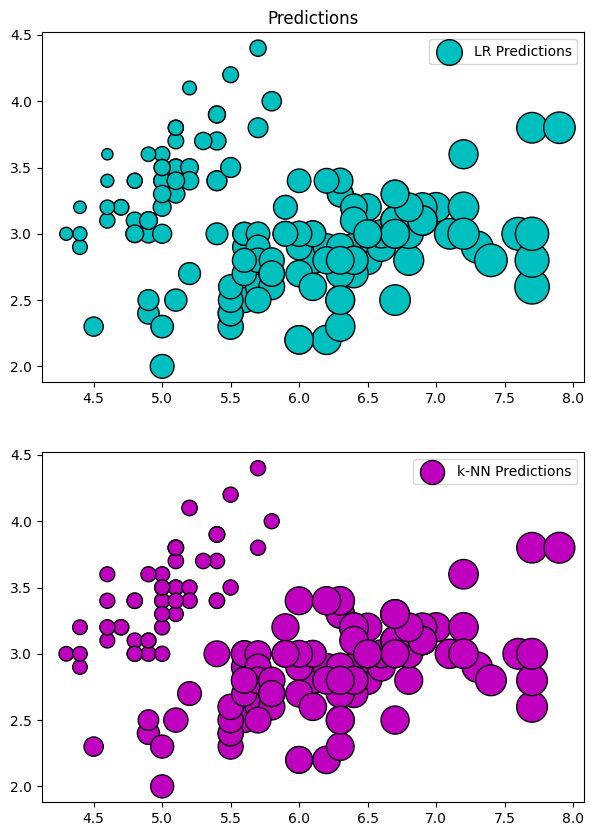

In [8]:
## 5. Visualize predictions from linear regression and k-NN regression.

f, ax = plt.subplots(nrows=2, figsize=(7, 10))
ax[0].set_title("Predictions")
ax[0].scatter(X[:, 0], X[:, 1], s=lr.predict(X)*80, label='LR Predictions', color='c', edgecolors='black')
ax[1].scatter(X[:, 0], X[:, 1], s=knnr.predict(X)*80, label='k-NN Predictions', color='m', edgecolors='black')
ax[0].legend()
ax[1].legend()

In [9]:
## 6. Extract the actual petal lengths for the setosa species.

setosa_idx = np.where(iris.target_names=='setosa')
setosa_mask = iris.target == setosa_idx[0]
y[setosa_mask][:5]

array([1.4, 1.4, 1.3, 1.5, 1.4])

In [10]:
## 7. Inspect k-NN regression predictions for the setosa species.

knnr.predict(X)[setosa_mask][:5]

array([1.46, 1.45, 1.51, 1.42, 1.46])

In [11]:
## 8. Inspect linear regression predictions for the setosa species.

lr.predict(X)[setosa_mask][:5]

array([1.84557896, 2.1597721 , 1.53692893, 1.49323201, 1.53415738])

In [12]:
## 9. Select the first data point as an example.

example_point = X[0]

In [13]:
## 10. Find the ten nearest neighbors and calculate their mean target value.

from sklearn.metrics import pairwise
distances_to_example = pairwise.pairwise_distances(X)[0]
ten_closest_points = X[np.argsort(distances_to_example)][:10]
ten_closest_y = y[np.argsort(distances_to_example)][:10]
ten_closest_y.mean()

np.float64(1.46)